KUMARA P.K.M.P. :  230353N

##### 1. Neural Network

In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
from datasets import load_dataset

# Download CIFAR-10 from Hugging Face (fast mirror)
ds = load_dataset("uoft-cs/cifar10")

# Convert images to normalized tensors (same normalization as original code)
def to_tensors(split):
    imgs = np.stack([np.array(im) for im in ds[split]['img']])   # shape (N, 32, 32, 3)
    x = torch.from_numpy(imgs).permute(0, 3, 1, 2).float() / 255.0
    x = (x - 0.5) / 0.5
    y = torch.tensor(ds[split]['label'])
    return x, y

x_tr, y_tr = to_tensors('train')
x_te, y_te = to_tensors('test')

batch_size = 50
trainset = torch.utils.data.TensorDataset(x_tr, y_tr)
testset  = torch.utils.data.TensorDataset(x_te, y_te)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)
testloader  = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False)

print("Done:", x_tr.shape, x_te.shape)

c:\Users\minsa\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\minsa\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\minsa\.cache\huggingface\hub\datasets--uoft-cs--cifar10. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an admini

Done: torch.Size([50000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])


Epoch 1/10, Loss: 1.9005
Epoch 2/10, Loss: 1.7168
Epoch 3/10, Loss: 1.6506
Epoch 4/10, Loss: 1.6032
Epoch 5/10, Loss: 1.5631
Epoch 6/10, Loss: 1.5296
Epoch 7/10, Loss: 1.4994
Epoch 8/10, Loss: 1.4722
Epoch 9/10, Loss: 1.4482
Epoch 10/10, Loss: 1.4262


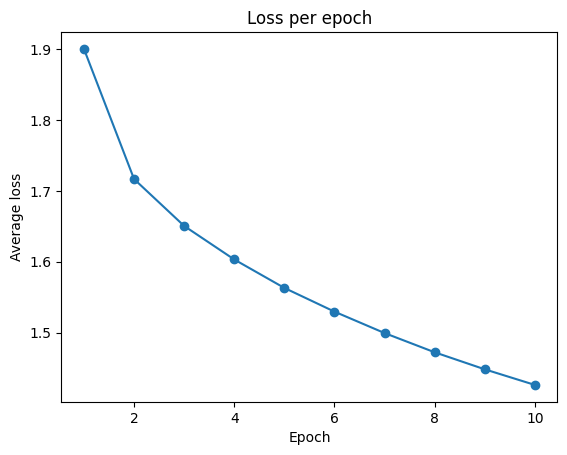

Training accuracy: 51.74%
Test accuracy: 47.54%


In [3]:
#new network parameters
Din = 3 * 32 * 32   # 3072
H = 100             # hidden nodes
K = 10              # classes
std = 1e-2

w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10     # epochs
lr = 0.1
lr_decay = 0.9
reg = 0

loss_history = []

def sigmoid(z):
    return 1.0 / (1.0 + torch.exp(-z))

def forward(x):
    h = sigmoid(x.mm(w1) + b1)
    scores = h.mm(w2) + b2
    return h, scores

#Training loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h, scores = forward(x_train)

        # Softmax to subtract max for numerical stability
        scores_shifted = scores - scores.max(dim=1, keepdim=True).values
        exp_scores = torch.exp(scores_shifted)
        probs = exp_scores / exp_scores.sum(dim=1, keepdim=True)

        # Cross entropy loss
        loss = -(1.0 / Ntr) * torch.sum(y_onehot * torch.log(probs + 1e-12)) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dscores = (probs - y_onehot) / Ntr
        dw2 = h.t().mm(dscores) + 2 * reg * w2
        db2 = dscores.sum(dim=0)
        dh = dscores.mm(w2.t())
        dz1 = dh * h * (1 - h)            # sigmoid derivative
        dw1 = x_train.t().mm(dz1) + 2 * reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t+1}/{iterations}, Loss: {running_loss/len(trainloader):.4f}")
    lr *= lr_decay

# Plot loss
epoch_avg = np.array(loss_history).reshape(10, -1).mean(axis=1)
plt.plot(range(1, 11), epoch_avg, marker='o')
plt.xlabel("Epoch"); plt.ylabel("Average loss"); plt.title("Loss per epoch")
plt.show()

# Accuracy helper
def accuracy(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, scores = forward(x)
            pred = torch.argmax(scores, dim=1)
            total += labels.size(0)
            correct += (pred == labels).sum().item()
    return 100 * correct / total

print(f"Training accuracy: {accuracy(trainloader):.2f}%")
print(f"Test accuracy: {accuracy(testloader):.2f}%")